In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 120)

OUTPUT_DIR = Path("output")
OUTPUT_DIR.mkdir(exist_ok=True)

In [2]:
df_original = pd.read_csv("titanic.csv")

print("Dataset shape:", df_original.shape)
display(df_original.head())
df_original.info()

Dataset shape: (891, 12)


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 118.9 KB


In [3]:
df_raw = df_original.copy()

# Add a demonstration-only record date.
# It is not a historical Titanic travel date.
df_raw["RecordDate"] = pd.date_range(
    start="2024-01-01",
    periods=len(df_raw),
    freq="D"
).strftime("%Y-%m-%d")

# Create controlled data-quality issues.
n = len(df_raw)
rng = np.random.default_rng(42)

# Inconsistent category formatting
if "Sex" in df_raw.columns:
    df_raw["Sex"] = df_raw["Sex"].astype(object)
    df_raw.loc[df_raw.index[0], "Sex"] = "Male"
    df_raw.loc[df_raw.index[1], "Sex"] = "F"
    df_raw.loc[df_raw.index[2], "Sex"] = " FEMALE "

if "Embarked" in df_raw.columns:
    df_raw["Embarked"] = df_raw["Embarked"].astype(object)
    df_raw.loc[df_raw.index[3], "Embarked"] = "southampton"
    df_raw.loc[df_raw.index[4], "Embarked"] = " cherbourg "

# Numeric columns stored as strings
if "Age" in df_raw.columns:
    df_raw["Age"] = df_raw["Age"].astype(object)
    df_raw.loc[df_raw.index[5], "Age"] = " 28 "

if "Fare" in df_raw.columns:
    df_raw["Fare"] = df_raw["Fare"].astype(object)
    df_raw.loc[df_raw.index[6], "Fare"] = "15.50"

# Mixed date formats in the demonstration column
df_raw["RecordDate"] = df_raw["RecordDate"].astype(object)
df_raw.loc[df_raw.index[7], "RecordDate"] = "08/01/2024"
df_raw.loc[df_raw.index[8], "RecordDate"] = "2024.01.09"

# Introduce a few additional missing values, where possible
for col in ["Age", "Fare", "Embarked"]:
    if col in df_raw.columns and len(df_raw) > 10:
        df_raw.loc[df_raw.index[10], col] = np.nan

# Add two duplicate records for demonstration
df_raw = pd.concat(
    [df_raw, df_raw.iloc[[0, 1]]],
    ignore_index=True
)

# Save the intentionally messy input
df_raw.to_csv(OUTPUT_DIR / "titanic_messy.csv", index=False)

print("Original rows:", len(df_original))
print("Messy rows:", len(df_raw))
display(df_raw.head(12))

Original rows: 891
Messy rows: 893


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked,RecordDate
0,1,0,3,"Braund, Mr. Owen Harris",Male,22.0,1,0,A/5 21171,7.25,NaN,S,2024-01-01
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",F,38.0,1,0,PC 17599,71.2833,C85,C,2024-01-02
2,3,1,3,"Heikkinen, Miss. Laina",FEMALE,26.0,0,0,STON/O2. 3101282,7.925,NaN,S,2024-01-03
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1,C123,southampton,2024-01-04
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.05,NaN,cherbourg,2024-01-05
5,6,0,3,"Moran, Mr. James",male,28,0,0,330877,8.4583,NaN,Q,2024-01-06
6,7,0,1,"McCarthy, Mr. Timothy J",male,54.0,0,0,17463,15.50,E46,S,2024-01-07
7,8,0,3,"Palsson, Master. Gosta Leonard",male,2.0,3,1,349909,21.075,NaN,S,08/01/2024
8,9,1,3,"Johnson, Mrs. Oscar W (Elisabeth Vilhelmina Berg)",female,27.0,0,2,347742,11.1333,NaN,S,2024.01.09
9,10,1,2,"Nasser, Mrs. Nicholas (Adele Achem)",female,14.0,1,0,237736,30.0708,NaN,C,2024-01-10


In [4]:
def create_quality_report(data):
    report = pd.DataFrame(index=data.columns)

    report["dtype"] = data.dtypes.astype(str)
    report["null_count"] = data.isna().sum()
    report["null_percent"] = (
        data.isna().mean().mul(100).round(2)
    )
    report["unique_values"] = data.nunique(dropna=True)

    return report.sort_values(
        by="null_count",
        ascending=False
    )

quality_before = create_quality_report(df_raw)

print("Rows:", len(df_raw))
print("Columns:", len(df_raw.columns))
print("Duplicate rows:", df_raw.duplicated().sum())

display(quality_before)

Rows: 893
Columns: 13
Duplicate rows: 2


,dtype,null_count,null_percent,unique_values
Cabin,str,688,77.04,147
Age,object,177,19.82,89
Embarked,object,3,0.34,5
Fare,object,1,0.11,249
PassengerId,int64,0,0.00,891
Sex,object,0,0.00,5
Name,str,0,0.00,891
Pclass,int64,0,0.00,3
Survived,int64,0,0.00,2
Ticket,str,0,0.00,681


In [5]:
# Numeric conversion is used for diagnosis only.
# It does not permanently modify df_raw.
numeric_candidates = [
    "Survived", "Pclass", "Age",
    "SibSp", "Parch", "Fare"
]

for col in numeric_candidates:
    if col in df_raw.columns:
        numeric_values = pd.to_numeric(
            df_raw[col], errors="coerce"
        )

        print(f"\n{col}")
        print("Minimum:", numeric_values.min())
        print("Maximum:", numeric_values.max())
        print("Non-numeric values:",
              (numeric_values.isna() & df_raw[col].notna()).sum())

# Check expected categorical values
if "Sex" in df_raw.columns:
    print("\nSex values:")
    print(df_raw["Sex"].value_counts(dropna=False))

if "Embarked" in df_raw.columns:
    print("\nEmbarked values:")
    print(df_raw["Embarked"].value_counts(dropna=False))


Survived
Minimum: 0
Maximum: 1
Non-numeric values: 0

Pclass
Minimum: 1
Maximum: 3
Non-numeric values: 0

Age
Minimum: 0.42
Maximum: 80.0
Non-numeric values: 0

SibSp
Minimum: 0
Maximum: 8
Non-numeric values: 0

Parch
Minimum: 0
Maximum: 6
Non-numeric values: 0

Fare
Minimum: 0.0
Maximum: 512.3292
Non-numeric values: 0

Sex values:
Sex
male        576
female      312
Male          2
F             2
 FEMALE       1
Name: count, dtype: int64

Embarked values:
Embarked
S              642
C              169
Q               77
NaN              3
southampton      1
 cherbourg       1
Name: count, dtype: int64


In [6]:
df = df_raw.copy()

duplicates_before = int(df.duplicated().sum())

df = df.drop_duplicates().copy()

duplicates_removed = duplicates_before - int(df.duplicated().sum())

print("Duplicate rows before cleaning:", duplicates_before)
print("Duplicate rows removed:", duplicates_removed)
print("Rows remaining:", len(df))

Duplicate rows before cleaning: 2
Duplicate rows removed: 2
Rows remaining: 891


In [7]:
# Remove leading/trailing whitespace from text columns
text_columns = df.select_dtypes(include=["object", "string"]).columns

for col in text_columns:
    df[col] = df[col].map(
        lambda value: value.strip() if isinstance(value, str) else value
    )

# Standardise gender
if "Sex" in df.columns:
    sex_map = {
        "male": "Male",
        "m": "Male",
        "female": "Female",
        "f": "Female"
    }

    df["Sex"] = (
        df["Sex"]
        .astype("string")
        .str.strip()
        .str.casefold()
        .map(sex_map)
    )

# Standardise embarkation ports
if "Embarked" in df.columns:
    embarked_map = {
        "s": "S",
        "southampton": "S",
        "q": "Q",
        "queenstown": "Q",
        "c": "C",
        "cherbourg": "C"
    }

    df["Embarked"] = (
        df["Embarked"]
        .astype("string")
        .str.strip()
        .str.casefold()
        .map(embarked_map)
    )

# Convert numeric fields even when they contain strings
numeric_columns = [
    "Survived", "Pclass", "Age",
    "SibSp", "Parch", "Fare"
]

for col in numeric_columns:
    if col in df.columns:
        df[col] = pd.to_numeric(df[col], errors="coerce")

# Identifiers must not be treated as measured numeric values
if "PassengerId" in df.columns:
    df["PassengerId"] = df["PassengerId"].astype("string")

# Convert the demonstration date column to datetime.
# Mixed date formats are parsed explicitly; unparseable values become NaT.
if "RecordDate" in df.columns:
    try:
        df["RecordDate"] = pd.to_datetime(
            df["RecordDate"],
            format="mixed",
            dayfirst=True,
            errors="coerce"
        )
    except (TypeError, ValueError):
        # Fallback for older pandas versions
        df["RecordDate"] = pd.to_datetime(
            df["RecordDate"],
            dayfirst=True,
            errors="coerce"
        )

print(df.dtypes)
display(df.head())

PassengerId            string
Survived                int64
Pclass                  int64
Name                      str
Sex                       str
Age                   float64
SibSp                   int64
Parch                   int64
Ticket                    str
Fare                  float64
Cabin                     str
Embarked                  str
RecordDate     datetime64[us]
dtype: object


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked,RecordDate
0,1,0,3,"Braund, Mr. Owen Harris",Male,22.0,1,0,A/5 21171,7.2500,NaN,S,2024-01-01
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",Female,38.0,1,0,PC 17599,71.2833,C85,C,2024-02-01
2,3,1,3,"Heikkinen, Miss. Laina",Female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S,2024-03-01
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",Female,35.0,1,0,113803,53.1000,C123,S,2024-04-01
4,5,0,3,"Allen, Mr. William Henry",Male,35.0,0,0,373450,8.0500,NaN,C,2024-05-01


In [9]:
# Invalid values are marked missing so they can be handled transparently.
if "Age" in df.columns:
    df.loc[df["Age"] < 0, "Age"] = np.nan

if "Fare" in df.columns:
    df.loc[df["Fare"] < 0, "Fare"] = np.nan

for col in ["SibSp", "Parch"]:
    if col in df.columns:
        df.loc[df[col] < 0, col] = np.nan

if "Survived" in df.columns:
    df.loc[~df["Survived"].isin([0, 1]), "Survived"] = np.nan

if "Pclass" in df.columns:
    df.loc[~df["Pclass"].isin([1, 2, 3]), "Pclass"] = np.nan

# Only retain valid documented category values
if "Sex" in df.columns:
    df.loc[~df["Sex"].isin(["Male", "Female"]), "Sex"] = pd.NA

if "Embarked" in df.columns:
    df.loc[~df["Embarked"].isin(["S", "C", "Q"]), "Embarked"] = pd.NA

In [10]:
# Age: median within passenger class and sex
if "Age" in df.columns:
    if {"Pclass", "Sex"}.issubset(df.columns):
        age_group_median = df.groupby(
            ["Pclass", "Sex"]
        )["Age"].transform("median")

        df["Age"] = df["Age"].fillna(age_group_median)

    # Fallback for groups that have no available median
    df["Age"] = df["Age"].fillna(df["Age"].median())

# Fare: median within passenger class
if "Fare" in df.columns:
    if "Pclass" in df.columns:
        fare_group_median = df.groupby(
            "Pclass"
        )["Fare"].transform("median")

        df["Fare"] = df["Fare"].fillna(fare_group_median)

    df["Fare"] = df["Fare"].fillna(df["Fare"].median())

# Embarked: most frequent valid category
if "Embarked" in df.columns:
    embarked_mode = df["Embarked"].mode(dropna=True)

    if not embarked_mode.empty:
        df["Embarked"] = df["Embarked"].fillna(embarked_mode.iloc[0])

# Cabin: preserve whether the cabin was recorded, then remove sparse column
if "Cabin" in df.columns:
    df["HasCabin"] = df["Cabin"].notna().astype("int8")
    df = df.drop(columns=["Cabin"])

# If the demonstration date is missing/unparseable, retain it as missing
# rather than inventing a date.
print("Remaining null values:")
display(df.isna().sum().sort_values(ascending=False))

Remaining null values:


PassengerId    0
Survived       0
Pclass         0
Name           0
Sex            0
Age            0
SibSp          0
Parch          0
Ticket         0
Fare           0
Embarked       0
RecordDate     0
HasCabin       0
dtype: int64

In [11]:
outlier_columns = [
    col for col in ["Age", "Fare", "SibSp", "Parch"]
    if col in df.columns
]

outlier_summary = []

for col in outlier_columns:
    series = df[col].dropna()

    q1 = series.quantile(0.25)
    q3 = series.quantile(0.75)
    iqr = q3 - q1

    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr

    mask = df[col].notna() & (
        (df[col] < lower_bound) |
        (df[col] > upper_bound)
    )

    df[f"{col}_Outlier"] = mask.astype("int8")

    outlier_summary.append({
        "Column": col,
        "Q1": q1,
        "Q3": q3,
        "IQR": iqr,
        "Lower_Bound": lower_bound,
        "Upper_Bound": upper_bound,
        "Outlier_Count": int(mask.sum())
    })

outlier_report = pd.DataFrame(outlier_summary)
display(outlier_report)

,Column,Q1,Q3,IQR,Lower_Bound,Upper_Bound,Outlier_Count
0,Age,22.0000,36.0,14.0000,1.000,57.0000,40
1,Fare,7.9104,31.0,23.0896,-26.724,65.6344,116
2,SibSp,0.0000,1.0,1.0000,-1.500,2.5000,46
3,Parch,0.0000,0.0,0.0000,0.000,0.0000,213


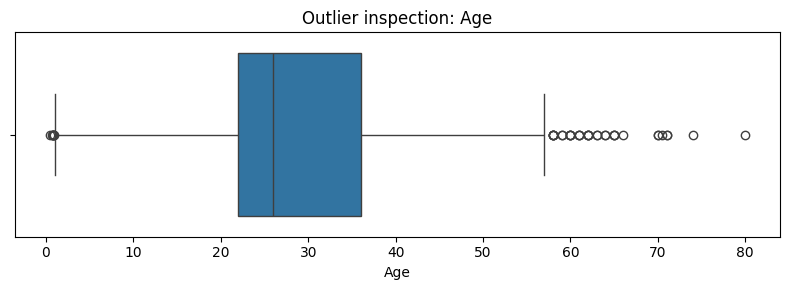

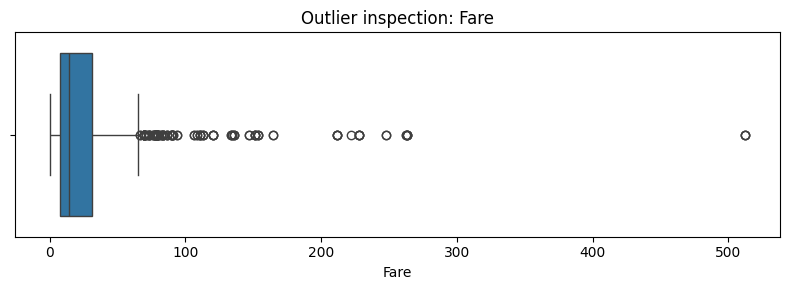

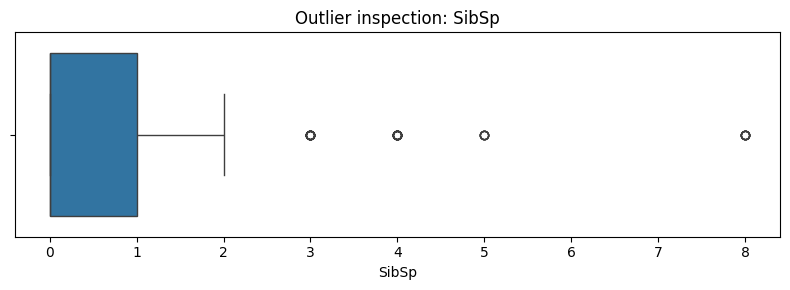

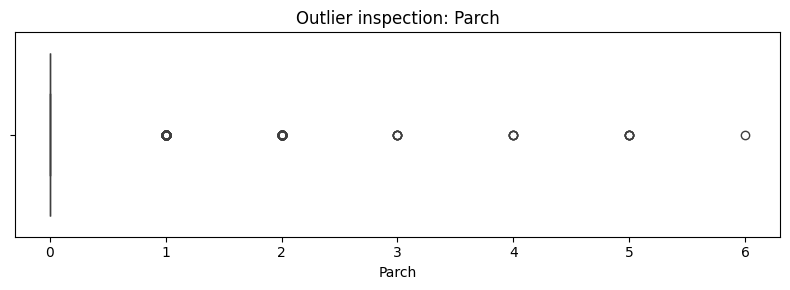

In [12]:
for col in outlier_columns:
    plt.figure(figsize=(8, 3))
    sns.boxplot(x=df[col])
    plt.title(f"Outlier inspection: {col}")
    plt.xlabel(col)
    plt.tight_layout()
    plt.show()

In [13]:
# Remove rows only when a required field remains invalid.
# The demonstration date is not part of the original Titanic data.
rows_before_required_check = len(df)

required_columns = [
    col for col in ["PassengerId", "Survived", "Pclass"]
    if col in df.columns
]

df = df.dropna(subset=required_columns).copy()

if "RecordDate" in df.columns:
    df = df.dropna(subset=["RecordDate"]).copy()

rows_removed_final = rows_before_required_check - len(df)

# Restore integer dtypes where fractional values are not meaningful.
for col in ["Survived", "Pclass", "SibSp", "Parch"]:
    if col in df.columns:
        df[col] = df[col].round().astype("Int64")

if "Age" in df.columns:
    df["Age"] = df["Age"].astype("float64")

if "Fare" in df.columns:
    df["Fare"] = df["Fare"].astype("float64")

if "PassengerId" in df.columns:
    df["PassengerId"] = df["PassengerId"].astype("string")

if "Sex" in df.columns:
    df["Sex"] = df["Sex"].astype("string")

if "Embarked" in df.columns:
    df["Embarked"] = df["Embarked"].astype("string")

if "RecordDate" in df.columns:
    df["RecordDate"] = pd.to_datetime(
        df["RecordDate"], errors="coerce"
    )

print("Rows removed in final validation:", rows_removed_final)
print("Final shape:", df.shape)
print("Duplicate rows remaining:", df.duplicated().sum())
print("Missing values remaining:")
display(df.isna().sum())
print("Final dtypes:")
display(df.dtypes)

Rows removed in final validation: 0
Final shape: (891, 17)
Duplicate rows remaining: 0
Missing values remaining:


PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age              0
SibSp            0
Parch            0
Ticket           0
Fare             0
Embarked         0
RecordDate       0
HasCabin         0
Age_Outlier      0
Fare_Outlier     0
SibSp_Outlier    0
Parch_Outlier    0
dtype: int64

Final dtypes:


PassengerId              string
Survived                  Int64
Pclass                    Int64
Name                        str
Sex                      string
Age                     float64
SibSp                     Int64
Parch                     Int64
Ticket                      str
Fare                    float64
Embarked                 string
RecordDate       datetime64[us]
HasCabin                   int8
Age_Outlier                int8
Fare_Outlier               int8
SibSp_Outlier              int8
Parch_Outlier              int8
dtype: object

In [16]:
from pandas.api.types import (
    is_string_dtype,
    is_datetime64_any_dtype,
    is_numeric_dtype,
    is_integer_dtype
)

def dtype_accuracy(data):
    """
    Check columns with explicit expected data types.
    Returns number correct, number checked, and percentage.
    """
    checks = {}

    if "PassengerId" in data.columns:
        checks["PassengerId"] = lambda s: is_string_dtype(s.dtype)

    if "RecordDate" in data.columns:
        checks["RecordDate"] = lambda s: is_datetime64_any_dtype(s.dtype)

    for col in ["Age", "Fare"]:
        if col in data.columns:
            checks[col] = lambda s: is_numeric_dtype(s.dtype)

    for col in ["Survived", "Pclass", "SibSp", "Parch"]:
        if col in data.columns:
            checks[col] = lambda s: is_integer_dtype(s.dtype)

    if not checks:
        return 0, 0, 100.0

    correct = sum(
        bool(checks[col](data[col]))
        for col in checks
    )

    total = len(checks)
    percentage = round(correct / total * 100, 2)

    return correct, total, percentage


def quality_metrics(data):
    correct, total, pct = dtype_accuracy(data)

    return {
        "Row_Count": len(data),
        "Total_Null_Cells": int(data.isna().sum().sum()),
        "Duplicate_Rows": int(data.duplicated().sum()),
        "Dtypes_Correct": f"{correct}/{total}",
        "Dtype_Accuracy_Percent": pct
    }


before_metrics = quality_metrics(df_raw)
after_metrics = quality_metrics(df)

comparison = pd.DataFrame(
    [before_metrics, after_metrics],
    index=["Before Cleaning", "After Cleaning"]
)

display(comparison)

,Row_Count,Total_Null_Cells,Duplicate_Rows,Dtypes_Correct,Dtype_Accuracy_Percent
Before Cleaning,893,869,2,4/8,50.0
After Cleaning,891,0,0,8/8,100.0


In [17]:
dtype_comparison = pd.DataFrame({
    "Before": df_raw.dtypes.astype(str),
    "After": df.dtypes.astype(str)
})

display(dtype_comparison)

,Before,After
Age,object,float64
Age_Outlier,NaN,int8
Cabin,str,NaN
Embarked,object,string
Fare,object,float64
Fare_Outlier,NaN,int8
HasCabin,NaN,int8
Name,str,str
Parch,int64,Int64
Parch_Outlier,NaN,int8


In [18]:
cleaned_path = OUTPUT_DIR / "titanic_cleaned.csv"
quality_path = OUTPUT_DIR / "data_quality_before_after.csv"
outlier_path = OUTPUT_DIR / "outlier_report.csv"
dtype_path = OUTPUT_DIR / "dtype_comparison.csv"

df.to_csv(cleaned_path, index=False)
comparison.to_csv(quality_path)
outlier_report.to_csv(outlier_path, index=False)
dtype_comparison.to_csv(dtype_path)

print("Files saved:")
print(cleaned_path)
print(quality_path)
print(outlier_path)
print(dtype_path)

Files saved:
output\titanic_cleaned.csv
output\data_quality_before_after.csv
output\outlier_report.csv
output\dtype_comparison.csv
